In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv('C:\\Users\\LENOVO\\End-to-End-Data-Science\\Project-02\\data\\WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.shape

(7043, 21)

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [12]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [13]:
df['TotalCharges'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: TotalCharges
Non-Null Count  Dtype 
--------------  ----- 
7043 non-null   object
dtypes: object(1)
memory usage: 55.2+ KB


In [14]:
pd.to_numeric(df['TotalCharges'], errors='coerce').isnull().sum()

np.int64(11)

In [15]:
bad = df[pd.to_numeric(df['TotalCharges'], errors='coerce').isnull()]
bad[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [16]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].isnull().sum(), df['TotalCharges'].dtype

(np.int64(0), dtype('float64'))

In [17]:
df = df.drop(columns=['customerID'])

In [18]:
df.duplicated().sum()

np.int64(22)

In [19]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [20]:
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    print(col, df[col].unique())


gender ['Female' 'Male']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [21]:
df.info()
df.isnull().sum().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


np.int64(0)

In [22]:
df['Churn'].mean()

np.float64(0.2653698707936959)

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


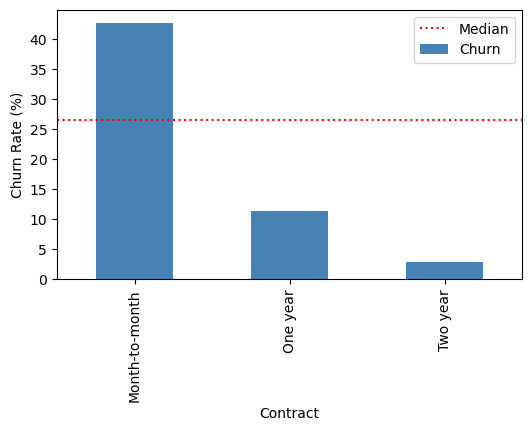

In [35]:
def churn_by(col):
    result = df.groupby(col)['Churn'].mean().sort_values(ascending=False) * 100
    print(result.round(1))
    result.plot(kind='bar', color='steelblue', figsize=(6, 3.5))
    plt.ylabel('Churn Rate (%)')
    plt.axhline(df['Churn'].mean() * 100, color='red', linestyle=':', label='Median')
    plt.legend()
    plt.show()

churn_by('Contract')

InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: Churn, dtype: float64


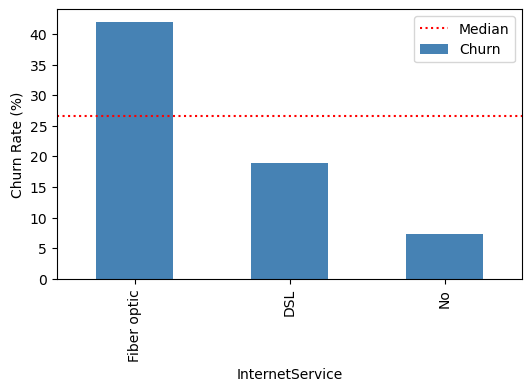

In [36]:
churn_by('InternetService')

PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: Churn, dtype: float64


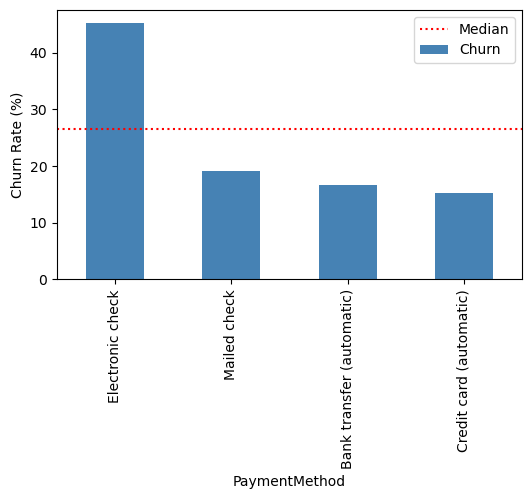

In [37]:
churn_by('PaymentMethod')

TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: Churn, dtype: float64


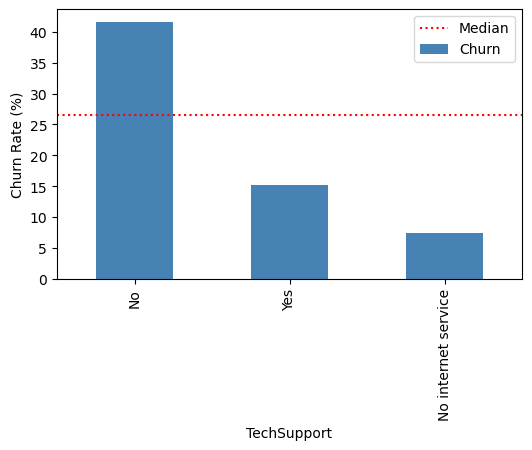

In [38]:
churn_by('TechSupport')

gender
Female    26.9
Male      26.2
Name: Churn, dtype: float64


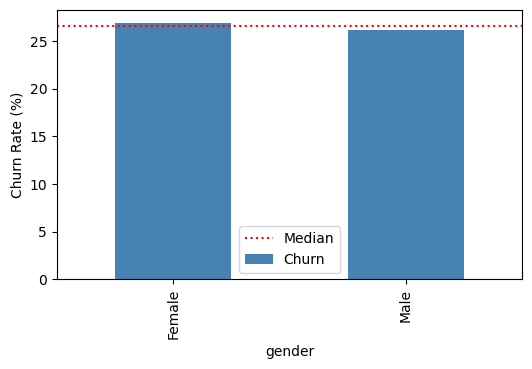

In [39]:
churn_by('gender')

SeniorCitizen
1    41.7
0    23.6
Name: Churn, dtype: float64


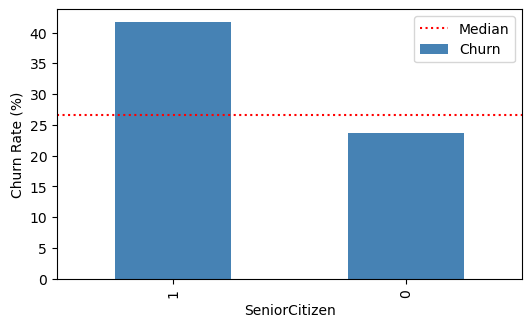

In [40]:
churn_by('SeniorCitizen')

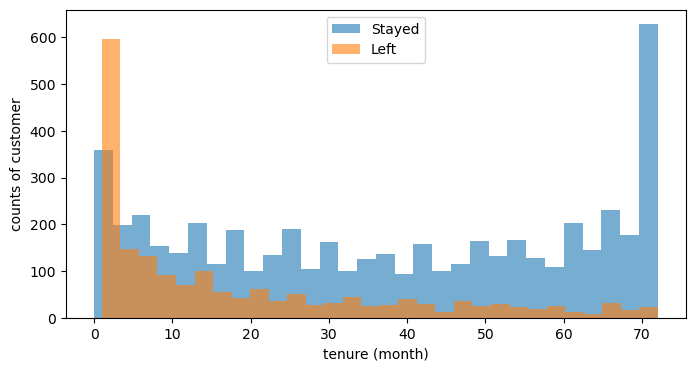

In [60]:
plt.figure(figsize=(8, 4))
plt.hist(df[df['Churn'] == 0]['tenure'], bins=30, alpha=0.6, label='Stayed')
plt.hist(df[df['Churn'] == 1]['tenure'], bins=30, alpha=0.6, label='Left')
plt.xlabel('tenure (month)')
plt.ylabel('counts of customer')
plt.legend()
plt.show()


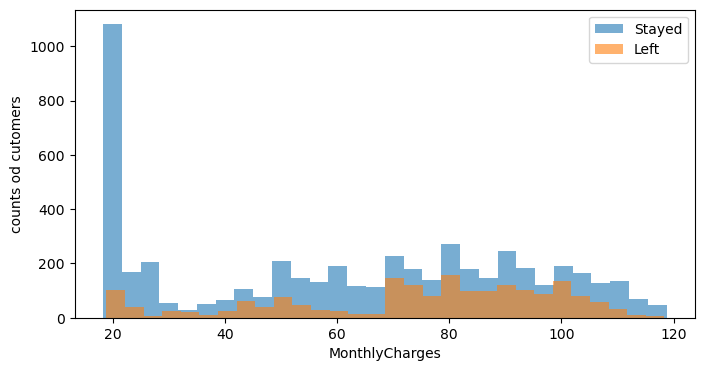

In [43]:
plt.figure(figsize=(8, 4))
plt.hist(df[df['Churn'] == 0]['MonthlyCharges'], bins=30, alpha=0.6, label='Stayed')
plt.hist(df[df['Churn'] == 1]['MonthlyCharges'], bins=30, alpha=0.6, label='Left')
plt.xlabel('MonthlyCharges')
plt.ylabel('counts od cutomers')
plt.legend()
plt.show()

In [47]:
df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean().round(1)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,37.6,61.3,2549.9
1,18.0,74.4,1531.8


In [48]:
df.groupby(['Contract', 'InternetService'])['Churn'].mean().mul(100).round(1).unstack()

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8


In [49]:
df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']].corr()['Churn'].sort_values()

tenure           -0.352229
TotalCharges     -0.198324
SeniorCitizen     0.150889
MonthlyCharges    0.193356
Churn             1.000000
Name: Churn, dtype: float64

In [50]:
df_encode = pd.get_dummies(df, drop_first=True, dtype=int)
df_encode.shape
df_encode.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [51]:
df_encode.dtypes.value_counts()

int64      29
float64     2
Name: count, dtype: int64

In [52]:
X = df_encode.drop('Churn', axis=1)
y = df_encode['Churn']

X.shape, y.shape

((7043, 30), (7043,))

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((5634, 30), (1409, 30))

In [54]:
print(y_train.mean(), y_test.mean())

0.2653532126375577 0.2654364797728886


In [55]:
X_train[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']].describe().loc[['min', 'max']]

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
min,0.0,18.40,0.0,0.0
max,72.0,118.75,8684.8,1.0


In [57]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

In [61]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

print('Dummy test accuracy:', dummy.score(X_test, y_test))


Dummy test accuracy: 0.7345635202271115


In [63]:
print('Dummy unique:', np.unique(dummy.predict(X_test)))

Dummy unique: [0]


In [64]:
log_reg.fit(X_train, y_train)

print('Train accuracy:', log_reg.score(X_train, y_train))
print('Test accuracy:', log_reg.score(X_test, y_test))

Train accuracy: 0.8065317713880015
Test accuracy: 0.8069552874378992


In [66]:
from sklearn.model_selection import cross_val_score

cv_dummy = cross_val_score(dummy, X_train, y_train, cv=5)
cv_log = cross_val_score(log_reg, X_train, y_train, cv=5)

print('Dummy cv:', cv_dummy.round(3), 'mean:', cv_dummy.mean().round(3))
print('LogReg cv:', cv_log.round(3), 'mean:', cv_log.mean().round(3))

Dummy cv: [0.735 0.735 0.735 0.735 0.734] mean: 0.735
LogReg cv: [0.829 0.801 0.807 0.793 0.791] mean: 0.804


In [67]:
pd.DataFrame({
    'Model': ['Dummy', 'Logistic Regression'],
    'CV accuracy': [cv_dummy.mean(), cv_log.mean()]
}).round(3)

,Model,CV accuracy
0,Dummy,0.735
1,Logistic Regression,0.804


In [68]:
y_pred = log_reg.predict(X_test)
print('Actual number of customers who left:', y_test.sum())
print('Number of customers predicted to leave:', y_pred.sum())
print('Number of correctly identified customers who left:', ((y_pred == 1) & (y_test == 1)).sum())

Actual number of customers who left: 374
Number of customers predicted to leave: 322
Number of correctly identified customers who left: 212


In [69]:
coefs = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': log_reg[-1].coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

coefs.head(10)

,feature,coefficient
1,tenure,-1.236528
2,MonthlyCharges,-0.920153
10,InternetService_Fiber optic,0.776154
25,Contract_Two year,-0.586859
3,TotalCharges,0.514285
24,Contract_One year,-0.285509
23,StreamingMovies_Yes,0.257227
21,StreamingTV_Yes,0.257144
9,MultipleLines_Yes,0.216167
26,PaperlessBilling_Yes,0.182034
